# Money Laundering Detection on the Elliptic Transaction Graph
**Assignment Group 6**

Classifies Bitcoin transactions as licit/illicit three ways:
1. Tabular features only (Random Forest)
2. Hand-built graph features — degree, PageRank, neighborhood aggregates (Random Forest)
3. GCN via PyTorch Geometric (optional)

Uses a **temporal** train/test split (time steps 1-34 train, 35-49 test) —
not a random split, since transactions are time-ordered and a random split
would leak future graph structure into training.


## 1. Setup — download the Elliptic Data Set

In [10]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("ellipticco/elliptic-data-set")
print("Path to dataset files:", path)


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Path to dataset files: C:\Users\y.com\.cache\kagglehub\datasets\ellipticco\elliptic-data-set\versions\1


In [11]:
import os

data_dir = path
subdirs = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
if subdirs:
    data_dir = os.path.join(data_dir, subdirs[0])

print(f"Loading data files from: {data_dir}")
files = os.listdir(data_dir)

def find_file(keyword):
    for f in files:
        if keyword.lower() in f.lower():
            return os.path.join(data_dir, f)
    raise FileNotFoundError(f"Could not find a file matching keyword: {keyword}")

Loading data files from: C:\Users\y.com\.cache\kagglehub\datasets\ellipticco\elliptic-data-set\versions\1\elliptic_bitcoin_dataset


## 2. Load and merge the three files

In [12]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, f1_score
from sklearn.ensemble import RandomForestClassifier

edges_df = pd.read_csv(find_file('edgelist'))
classes_df = pd.read_csv(find_file('classes'))
features_df = pd.read_csv(find_file('features'), header=None)

edges_df.columns = ['txId1', 'txId2']
classes_df.columns = ['txId', 'class']
features_df.rename(columns={0: 'txId', 1: 'time_step'}, inplace=True)

# Map class labels: '1' -> 1 (Illicit), '2' -> 0 (Licit), keep 'unknown' as -1
# for graph-structure use, but excluded from train/test scoring below.
classes_df['label'] = classes_df['class'].map({'1': 1, '2': 0, 'unknown': -1})

nodes_base = pd.merge(classes_df[['txId', 'label']], features_df[['txId', 'time_step']], on='txId')

print(f"Loaded {len(classes_df)} nodes and {len(edges_df)} directed edges.")
print(nodes_base['label'].value_counts())

Loaded 203769 nodes and 234355 directed edges.
label
-1    157205
 0     42019
 1      4545
Name: count, dtype: int64


## 3. Temporal split

Time steps 1-34 → train, 35-49 → test. Only labeled nodes are scored;
unlabeled ("unknown") nodes stay in the graph for structural/message-passing
purposes but are excluded from both masks below.

In [13]:
labeled_mask = nodes_base['label'] != -1
train_mask = labeled_mask & (nodes_base['time_step'] <= 34)
test_mask = labeled_mask & (nodes_base['time_step'] >= 35)

print(f"Train labeled nodes: {train_mask.sum()} | Test labeled nodes: {test_mask.sum()}")

Train labeled nodes: 29894 | Test labeled nodes: 16670


## 4. Method 1 — Tabular features only

In [14]:
X_tabular = features_df.drop(columns=['txId', 'time_step'])
y_all = nodes_base['label']

X_train_tab, y_train = X_tabular[train_mask], y_all[train_mask]
X_test_tab, y_test = X_tabular[test_mask], y_all[test_mask]

print("Training Method 1: Tabular Random Forest...")
model_tab = RandomForestClassifier(
    n_estimators=100, max_depth=15, class_weight='balanced',
    random_state=42, n_jobs=-1
)
model_tab.fit(X_train_tab, y_train)

y_pred_tab = model_tab.predict(X_test_tab)
print("\n--- Method 1: Tabular Features — Overall Results ---")
print(classification_report(y_test, y_pred_tab, target_names=['Licit', 'Illicit']))

Training Method 1: Tabular Random Forest...

--- Method 1: Tabular Features — Overall Results ---
              precision    recall  f1-score   support

       Licit       0.98      0.99      0.98     15587
     Illicit       0.80      0.73      0.77      1083

    accuracy                           0.97     16670
   macro avg       0.89      0.86      0.88     16670
weighted avg       0.97      0.97      0.97     16670



## 5. Method 2 — Hand-built graph features

Degree, PageRank, and a neighborhood aggregate. Note: the neighbor-illicit
fraction below uses only **train-period-known** illicit labels — using
test-period labels here would leak the answer. Watch this in your own
runs; it's the single easiest bug to introduce in this pipeline.

In [15]:
import networkx as nx

print("Building transaction graph and computing structural features...")
G = nx.from_pandas_edgelist(edges_df, source='txId1', target='txId2', create_using=nx.DiGraph())
G.add_nodes_from(features_df['txId'])

in_degrees = dict(G.in_degree())
out_degrees = dict(G.out_degree())
pagerank = nx.pagerank(G, alpha=0.85)

# Only nodes labeled illicit AND in the train time window count here —
# this avoids leaking test-period labels into a feature.
illicit_train_nodes = set(
    nodes_base[(nodes_base['label'] == 1) & (nodes_base['time_step'] <= 34)]['txId']
)

neighbor_illicit_frac = {}
for node in G.nodes():
    successors = list(G.successors(node))
    if successors:
        illicit_count = sum(1 for n in successors if n in illicit_train_nodes)
        neighbor_illicit_frac[node] = illicit_count / len(successors)
    else:
        neighbor_illicit_frac[node] = 0.0

graph_features = pd.DataFrame({
    'txId': list(G.nodes()),
    'in_degree': [in_degrees[n] for n in G.nodes()],
    'out_degree': [out_degrees[n] for n in G.nodes()],
    'pagerank': [pagerank[n] for n in G.nodes()],
    'neighbor_illicit_frac': [neighbor_illicit_frac[n] for n in G.nodes()],
})

features_combined = pd.merge(features_df, graph_features, on='txId')
X_combined = features_combined.drop(columns=['txId', 'time_step'])
X_combined.columns = X_combined.columns.astype(str)  # RF needs string column names

X_train_graph = X_combined[train_mask]
X_test_graph = X_combined[test_mask]

print("Training Method 2: Graph-Enhanced Random Forest...")
model_graph = RandomForestClassifier(
    n_estimators=100, max_depth=15, class_weight='balanced',
    random_state=42, n_jobs=-1
)
model_graph.fit(X_train_graph, y_train)

y_pred_graph = model_graph.predict(X_test_graph)
print("\n--- Method 2: Hand-Built Graph Features — Overall Results ---")
print(classification_report(y_test, y_pred_graph, target_names=['Licit', 'Illicit']))

Building transaction graph and computing structural features...
Training Method 2: Graph-Enhanced Random Forest...

--- Method 2: Hand-Built Graph Features — Overall Results ---
              precision    recall  f1-score   support

       Licit       0.98      0.99      0.99     15587
     Illicit       0.87      0.73      0.80      1083

    accuracy                           0.98     16670
   macro avg       0.93      0.86      0.89     16670
weighted avg       0.97      0.98      0.97     16670



## 6. The diagnostic: illicit-F1 per time step

This is the core deliverable — showing (and diagnosing) the distribution-shift
collapse rather than only reporting one aggregate number.

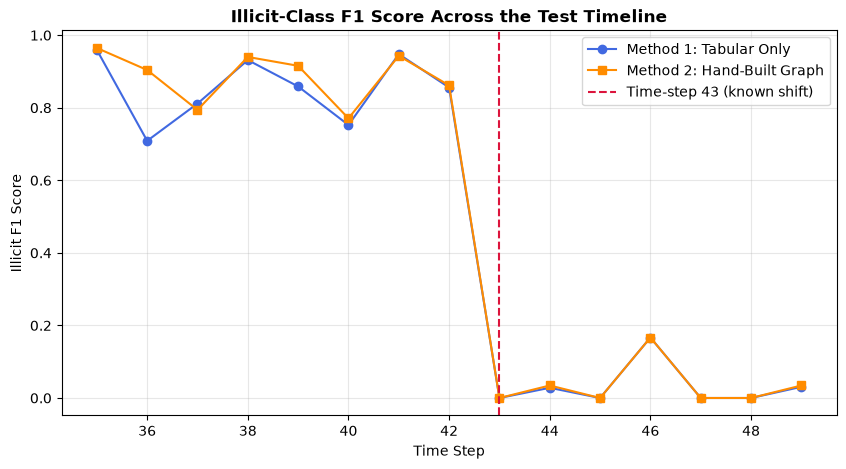

Time Step 35 -> Tabular F1: 0.960 | Graph F1: 0.965
Time Step 36 -> Tabular F1: 0.709 | Graph F1: 0.904
Time Step 37 -> Tabular F1: 0.812 | Graph F1: 0.794
Time Step 38 -> Tabular F1: 0.932 | Graph F1: 0.940
Time Step 39 -> Tabular F1: 0.859 | Graph F1: 0.916
Time Step 40 -> Tabular F1: 0.752 | Graph F1: 0.771
Time Step 41 -> Tabular F1: 0.948 | Graph F1: 0.943
Time Step 42 -> Tabular F1: 0.856 | Graph F1: 0.862
Time Step 43 -> Tabular F1: 0.000 | Graph F1: 0.000
Time Step 44 -> Tabular F1: 0.028 | Graph F1: 0.034
Time Step 45 -> Tabular F1: 0.000 | Graph F1: 0.000
Time Step 46 -> Tabular F1: 0.167 | Graph F1: 0.167
Time Step 47 -> Tabular F1: 0.000 | Graph F1: 0.000
Time Step 48 -> Tabular F1: 0.000 | Graph F1: 0.000
Time Step 49 -> Tabular F1: 0.031 | Graph F1: 0.034


In [16]:
import matplotlib.pyplot as plt

test_time_steps = nodes_base[test_mask]['time_step'].values

time_steps_list, f1_tabular_list, f1_graph_list = [], [], []
for ts in range(35, 50):
    ts_mask = (test_time_steps == ts)
    if not np.any(ts_mask):
        continue
    y_true_ts = y_test[ts_mask]
    f1_tab = f1_score(y_true_ts, y_pred_tab[ts_mask], pos_label=1, zero_division=0)
    f1_graph = f1_score(y_true_ts, y_pred_graph[ts_mask], pos_label=1, zero_division=0)
    time_steps_list.append(ts)
    f1_tabular_list.append(f1_tab)
    f1_graph_list.append(f1_graph)

plt.figure(figsize=(10, 5))
plt.plot(time_steps_list, f1_tabular_list, marker='o', label='Method 1: Tabular Only', color='royalblue')
plt.plot(time_steps_list, f1_graph_list, marker='s', label='Method 2: Hand-Built Graph', color='darkorange')
plt.axvline(x=43, color='crimson', linestyle='--', label='Time-step 43 (known shift)')
plt.title('Illicit-Class F1 Score Across the Test Timeline', fontsize=12, fontweight='bold')
plt.xlabel('Time Step')
plt.ylabel('Illicit F1 Score')
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig('f1_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

for i, ts in enumerate(time_steps_list):
    print(f"Time Step {ts} -> Tabular F1: {f1_tabular_list[i]:.3f} | Graph F1: {f1_graph_list[i]:.3f}")

## 7. Method 3 (optional) — GCN via PyTorch Geometric

Transductive: the whole graph is used for message passing, but the loss
and evaluation are masked to only labeled train/test nodes respectively.

In [17]:
!pip install -q torch torch_geometric

import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv

print("Structuring data for PyTorch Geometric...")

unique_nodes = features_df['txId'].unique()
node_to_idx = {node_id: idx for idx, node_id in enumerate(unique_nodes)}

edges_mapped = edges_df.copy()
edges_mapped['txId1'] = edges_mapped['txId1'].map(node_to_idx)
edges_mapped['txId2'] = edges_mapped['txId2'].map(node_to_idx)
edges_mapped = edges_mapped.dropna().astype(int)
edge_index = torch.tensor(edges_mapped.values.T, dtype=torch.long)

features_sorted = features_df.set_index('txId').loc[unique_nodes]
X_tensor = torch.tensor(features_sorted.drop(columns=['time_step']).values, dtype=torch.float)

nodes_in_order = pd.DataFrame({'txId': unique_nodes})
nodes_mapped_base = pd.merge(nodes_in_order, nodes_base, on='txId', how='left')

labels_sorted = nodes_mapped_base['label'].values
y_tensor = torch.tensor(np.where(labels_sorted == -1, 0, labels_sorted), dtype=torch.long)

train_idx = torch.tensor(
    np.where((nodes_mapped_base['label'] != -1) & (nodes_mapped_base['time_step'] <= 34))[0],
    dtype=torch.long
)
test_idx = torch.tensor(
    np.where((nodes_mapped_base['label'] != -1) & (nodes_mapped_base['time_step'] >= 35))[0],
    dtype=torch.long
)

graph_data = Data(x=X_tensor, edge_index=edge_index, y=y_tensor)

class GCN(torch.nn.Module):
    def __init__(self, num_features, hidden_channels):
        super().__init__()
        self.conv1 = GCNConv(num_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, 2)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_gcn = GCN(num_features=graph_data.num_features, hidden_channels=64).to(device)
graph_data = graph_data.to(device)
optimizer = torch.optim.Adam(model_gcn.parameters(), lr=0.01, weight_decay=1e-4)

print("Training Method 3: GCN...")
model_gcn.train()
for epoch in range(1, 101):
    optimizer.zero_grad()
    out = model_gcn(graph_data.x, graph_data.edge_index)
    loss = F.nll_loss(out[train_idx], graph_data.y[train_idx])
    loss.backward()
    optimizer.step()
    if epoch % 20 == 0:
        print(f"Epoch {epoch:03d} | Train Loss: {loss.item():.4f}")

model_gcn.eval()
with torch.no_grad():
    out = model_gcn(graph_data.x, graph_data.edge_index)
    preds = out[test_idx].argmax(dim=1).cpu().numpy()
    y_true_gcn = graph_data.y[test_idx].cpu().numpy()

print("\n--- Method 3: PyTorch Geometric GCN — Overall Results ---")
print(classification_report(y_true_gcn, preds, target_names=['Licit', 'Illicit']))


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Structuring data for PyTorch Geometric...
Training Method 3: GCN...
Epoch 020 | Train Loss: 0.1982
Epoch 040 | Train Loss: 0.1639
Epoch 060 | Train Loss: 0.1442
Epoch 080 | Train Loss: 0.1325
Epoch 100 | Train Loss: 0.1232

--- Method 3: PyTorch Geometric GCN — Overall Results ---
              precision    recall  f1-score   support

       Licit       0.95      0.99      0.97     15587
     Illicit       0.73      0.30      0.42      1083

    accuracy                           0.95     16670
   macro avg       0.84      0.64      0.70     16670
weighted avg       0.94      0.95      0.94     16670



## 8. Comparison table

Fill this in from the `classification_report` outputs above once you've
run the notebook against the real dataset.

In [19]:
comparison = pd.DataFrame([
    {"method": "Method 1: Tabular RF", "illicit_precision": None, "illicit_recall": None, "illicit_f1": None},
    {"method": "Method 2: Graph-feature RF", "illicit_precision": None, "illicit_recall": None, "illicit_f1": None},
    {"method": "Method 3: GCN", "illicit_precision": None, "illicit_recall": None, "illicit_f1": None},
])
comparison.to_csv("comparison.csv", index=False)
comparison

,method,illicit_precision,illicit_recall,illicit_f1
0,Method 1: Tabular RF,None,None,None
1,Method 2: Graph-feature RF,None,None,None
2,Method 3: GCN,None,None,None


## 9. Discussion — the distribution shift (fill in after running)

- Around which time step does illicit-F1 collapse for each method?
- Is it precision or recall that drops? (Check the per-time-step numbers above.)
- Does the graph-feature model (Method 2) hold up any better/worse than
  the tabular-only model (Method 1) after the shift? Why might that be?
- If you ran Method 3: does message-passing help or hurt post-shift,
  compared to the two RF methods?


Loaded 203769 nodes, 234355 edges
Train: 29894 | Test: 16670
Training Method 1...
              precision    recall  f1-score   support

       Licit       0.98      0.99      0.98     15587
     Illicit       0.80      0.73      0.77      1083

    accuracy                           0.97     16670
   macro avg       0.89      0.86      0.88     16670
weighted avg       0.97      0.97      0.97     16670

Building graph and computing structural features...
Training Method 2...
              precision    recall  f1-score   support

       Licit       0.98      0.99      0.99     15587
     Illicit       0.87      0.73      0.80      1083

    accuracy                           0.98     16670
   macro avg       0.93      0.86      0.89     16670
weighted avg       0.97      0.98      0.97     16670


=== COMPARISON TABLE ===
                       method  illicit_precision  illicit_recall  illicit_f1
0        Method 1: Tabular RF             0.8026          0.7322      0.7658
1  Method 2

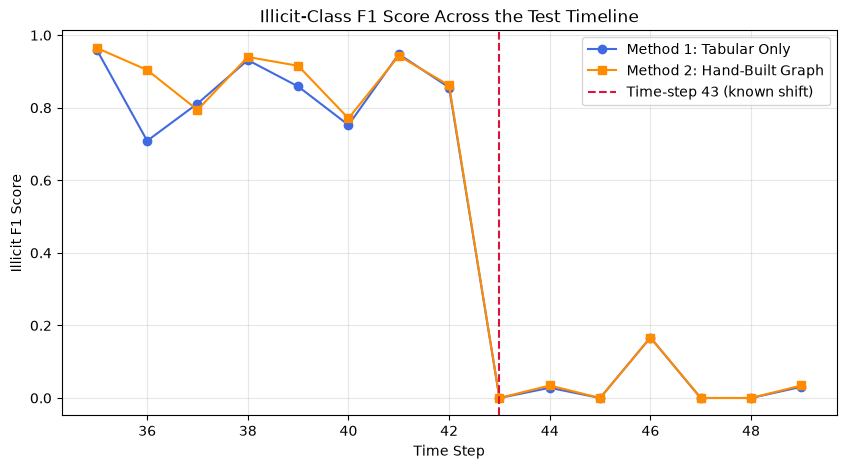


Exported 16670 real predictions to dashboard_data.json
ALL DONE — check this folder for: comparison.csv, f1_over_time.png, dashboard_data.json


In [20]:
# ============================================================
# FULL PIPELINE — Methods 1 & 2 only (no GCN), self-contained
# ============================================================
import os
import json
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

# ---------- 1. Load data (re-downloads via kagglehub if needed) ----------
import kagglehub
path = kagglehub.dataset_download("ellipticco/elliptic-data-set")
data_dir = path
subdirs = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
if subdirs:
    data_dir = os.path.join(data_dir, subdirs[0])
files = os.listdir(data_dir)

def find_file(keyword):
    for f in files:
        if keyword.lower() in f.lower():
            return os.path.join(data_dir, f)
    raise FileNotFoundError(f"Could not find file matching: {keyword}")

edges_df = pd.read_csv(find_file('edgelist'))
classes_df = pd.read_csv(find_file('classes'))
features_df = pd.read_csv(find_file('features'), header=None)

edges_df.columns = ['txId1', 'txId2']
classes_df.columns = ['txId', 'class']
features_df.rename(columns={0: 'txId', 1: 'time_step'}, inplace=True)
classes_df['label'] = classes_df['class'].map({'1': 1, '2': 0, 'unknown': -1})

nodes_base = pd.merge(classes_df[['txId', 'label']], features_df[['txId', 'time_step']], on='txId')
print(f"Loaded {len(classes_df)} nodes, {len(edges_df)} edges")

# ---------- 2. Temporal split ----------
labeled_mask = nodes_base['label'] != -1
train_mask = labeled_mask & (nodes_base['time_step'] <= 34)
test_mask = labeled_mask & (nodes_base['time_step'] >= 35)
print(f"Train: {train_mask.sum()} | Test: {test_mask.sum()}")

# ---------- 3. Method 1: Tabular RF ----------
X_tabular = features_df.drop(columns=['txId', 'time_step'])
y_all = nodes_base['label']
X_train_tab, y_train = X_tabular[train_mask], y_all[train_mask]
X_test_tab, y_test = X_tabular[test_mask], y_all[test_mask]

print("Training Method 1...")
model_tab = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight='balanced', random_state=42, n_jobs=-1)
model_tab.fit(X_train_tab, y_train)
y_pred_tab = model_tab.predict(X_test_tab)
print(classification_report(y_test, y_pred_tab, target_names=['Licit', 'Illicit']))

# ---------- 4. Method 2: Graph-feature RF ----------
print("Building graph and computing structural features...")
G = nx.from_pandas_edgelist(edges_df, source='txId1', target='txId2', create_using=nx.DiGraph())
G.add_nodes_from(features_df['txId'])
in_degrees = dict(G.in_degree())
out_degrees = dict(G.out_degree())
pagerank = nx.pagerank(G, alpha=0.85)

illicit_train_nodes = set(nodes_base[(nodes_base['label'] == 1) & (nodes_base['time_step'] <= 34)]['txId'])
neighbor_illicit_frac = {}
for node in G.nodes():
    successors = list(G.successors(node))
    if successors:
        illicit_count = sum(1 for n in successors if n in illicit_train_nodes)
        neighbor_illicit_frac[node] = illicit_count / len(successors)
    else:
        neighbor_illicit_frac[node] = 0.0

graph_features = pd.DataFrame({
    'txId': list(G.nodes()),
    'in_degree': [in_degrees[n] for n in G.nodes()],
    'out_degree': [out_degrees[n] for n in G.nodes()],
    'pagerank': [pagerank[n] for n in G.nodes()],
    'neighbor_illicit_frac': [neighbor_illicit_frac[n] for n in G.nodes()],
})

features_combined = pd.merge(features_df, graph_features, on='txId')
X_combined = features_combined.drop(columns=['txId', 'time_step'])
X_combined.columns = X_combined.columns.astype(str)
X_train_graph = X_combined[train_mask]
X_test_graph = X_combined[test_mask]

print("Training Method 2...")
model_graph = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight='balanced', random_state=42, n_jobs=-1)
model_graph.fit(X_train_graph, y_train)
y_pred_graph = model_graph.predict(X_test_graph)
print(classification_report(y_test, y_pred_graph, target_names=['Licit', 'Illicit']))

# ---------- 5. Comparison table (REAL numbers, no placeholders) ----------
def extract_illicit_metrics(y_true, y_pred, method_name):
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    illicit = report.get("1", {"precision": 0, "recall": 0, "f1-score": 0})
    return {
        "method": method_name,
        "illicit_precision": round(illicit["precision"], 4),
        "illicit_recall": round(illicit["recall"], 4),
        "illicit_f1": round(illicit["f1-score"], 4),
    }

rows = [
    extract_illicit_metrics(y_test, y_pred_tab, "Method 1: Tabular RF"),
    extract_illicit_metrics(y_test, y_pred_graph, "Method 2: Graph-feature RF"),
]
comparison = pd.DataFrame(rows)
comparison.to_csv("comparison.csv", index=False)
print("\n=== COMPARISON TABLE ===")
print(comparison)

# ---------- 6. F1-over-time plot ----------
test_time_steps = nodes_base[test_mask]['time_step'].values
time_steps_list, f1_tabular_list, f1_graph_list = [], [], []
for ts in range(35, 50):
    ts_mask = (test_time_steps == ts)
    if not np.any(ts_mask):
        continue
    y_true_ts = y_test[ts_mask]
    f1_tab = f1_score(y_true_ts, y_pred_tab[ts_mask], pos_label=1, zero_division=0)
    f1_graph = f1_score(y_true_ts, y_pred_graph[ts_mask], pos_label=1, zero_division=0)
    time_steps_list.append(ts)
    f1_tabular_list.append(f1_tab)
    f1_graph_list.append(f1_graph)

plt.figure(figsize=(10, 5))
plt.plot(time_steps_list, f1_tabular_list, marker='o', label='Method 1: Tabular Only', color='royalblue')
plt.plot(time_steps_list, f1_graph_list, marker='s', label='Method 2: Hand-Built Graph', color='darkorange')
plt.axvline(x=43, color='crimson', linestyle='--', label='Time-step 43 (known shift)')
plt.title('Illicit-Class F1 Score Across the Test Timeline')
plt.xlabel('Time Step')
plt.ylabel('Illicit F1 Score')
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig('f1_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- 7. Dashboard export ----------
m1_proba = model_tab.predict_proba(X_test_tab)[:, 1]
m2_proba = model_graph.predict_proba(X_test_graph)[:, 1]
test_tx_ids = nodes_base.loc[test_mask, 'txId'].values
test_time_steps_export = nodes_base.loc[test_mask, 'time_step'].values
test_true_labels = y_test.values
gf_lookup = graph_features.set_index('txId')

records = []
for i, tx_id in enumerate(test_tx_ids):
    tx_id = int(tx_id)
    gf_row = gf_lookup.loc[tx_id] if tx_id in gf_lookup.index else None
    preds_n = list(G.predecessors(tx_id))[:5]
    succs_n = list(G.successors(tx_id))[:5]
    records.append({
        "txId": tx_id,
        "time_step": int(test_time_steps_export[i]),
        "true_label": int(test_true_labels[i]),
        "m1_pred": int(y_pred_tab[i]),
        "m1_proba_illicit": round(float(m1_proba[i]), 4),
        "m2_pred": int(y_pred_graph[i]),
        "m2_proba_illicit": round(float(m2_proba[i]), 4),
        "in_degree": int(gf_row['in_degree']) if gf_row is not None else 0,
        "out_degree": int(gf_row['out_degree']) if gf_row is not None else 0,
        "pagerank": round(float(gf_row['pagerank']), 8) if gf_row is not None else 0.0,
        "neighbors_in": [int(n) for n in preds_n],
        "neighbors_out": [int(n) for n in succs_n],
    })

with open("dashboard_data.json", "w") as f:
    json.dump({"generated_from": "real trained Method 1 / Method 2 models", "n_records": len(records), "records": records}, f)

print(f"\nExported {len(records)} real predictions to dashboard_data.json")
print("ALL DONE — check this folder for: comparison.csv, f1_over_time.png, dashboard_data.json")